# 液膜聚合

圆管半径 $R=250\,\mu\mathrm{m}$，液相黏度 $0.05\,\mathrm{Pa\,s}$，表面张力 $0.02\,\mathrm{N/m}$。

## 图 1 · 气芯半径随物理时间变化

采用你指定的原图和数据截点。

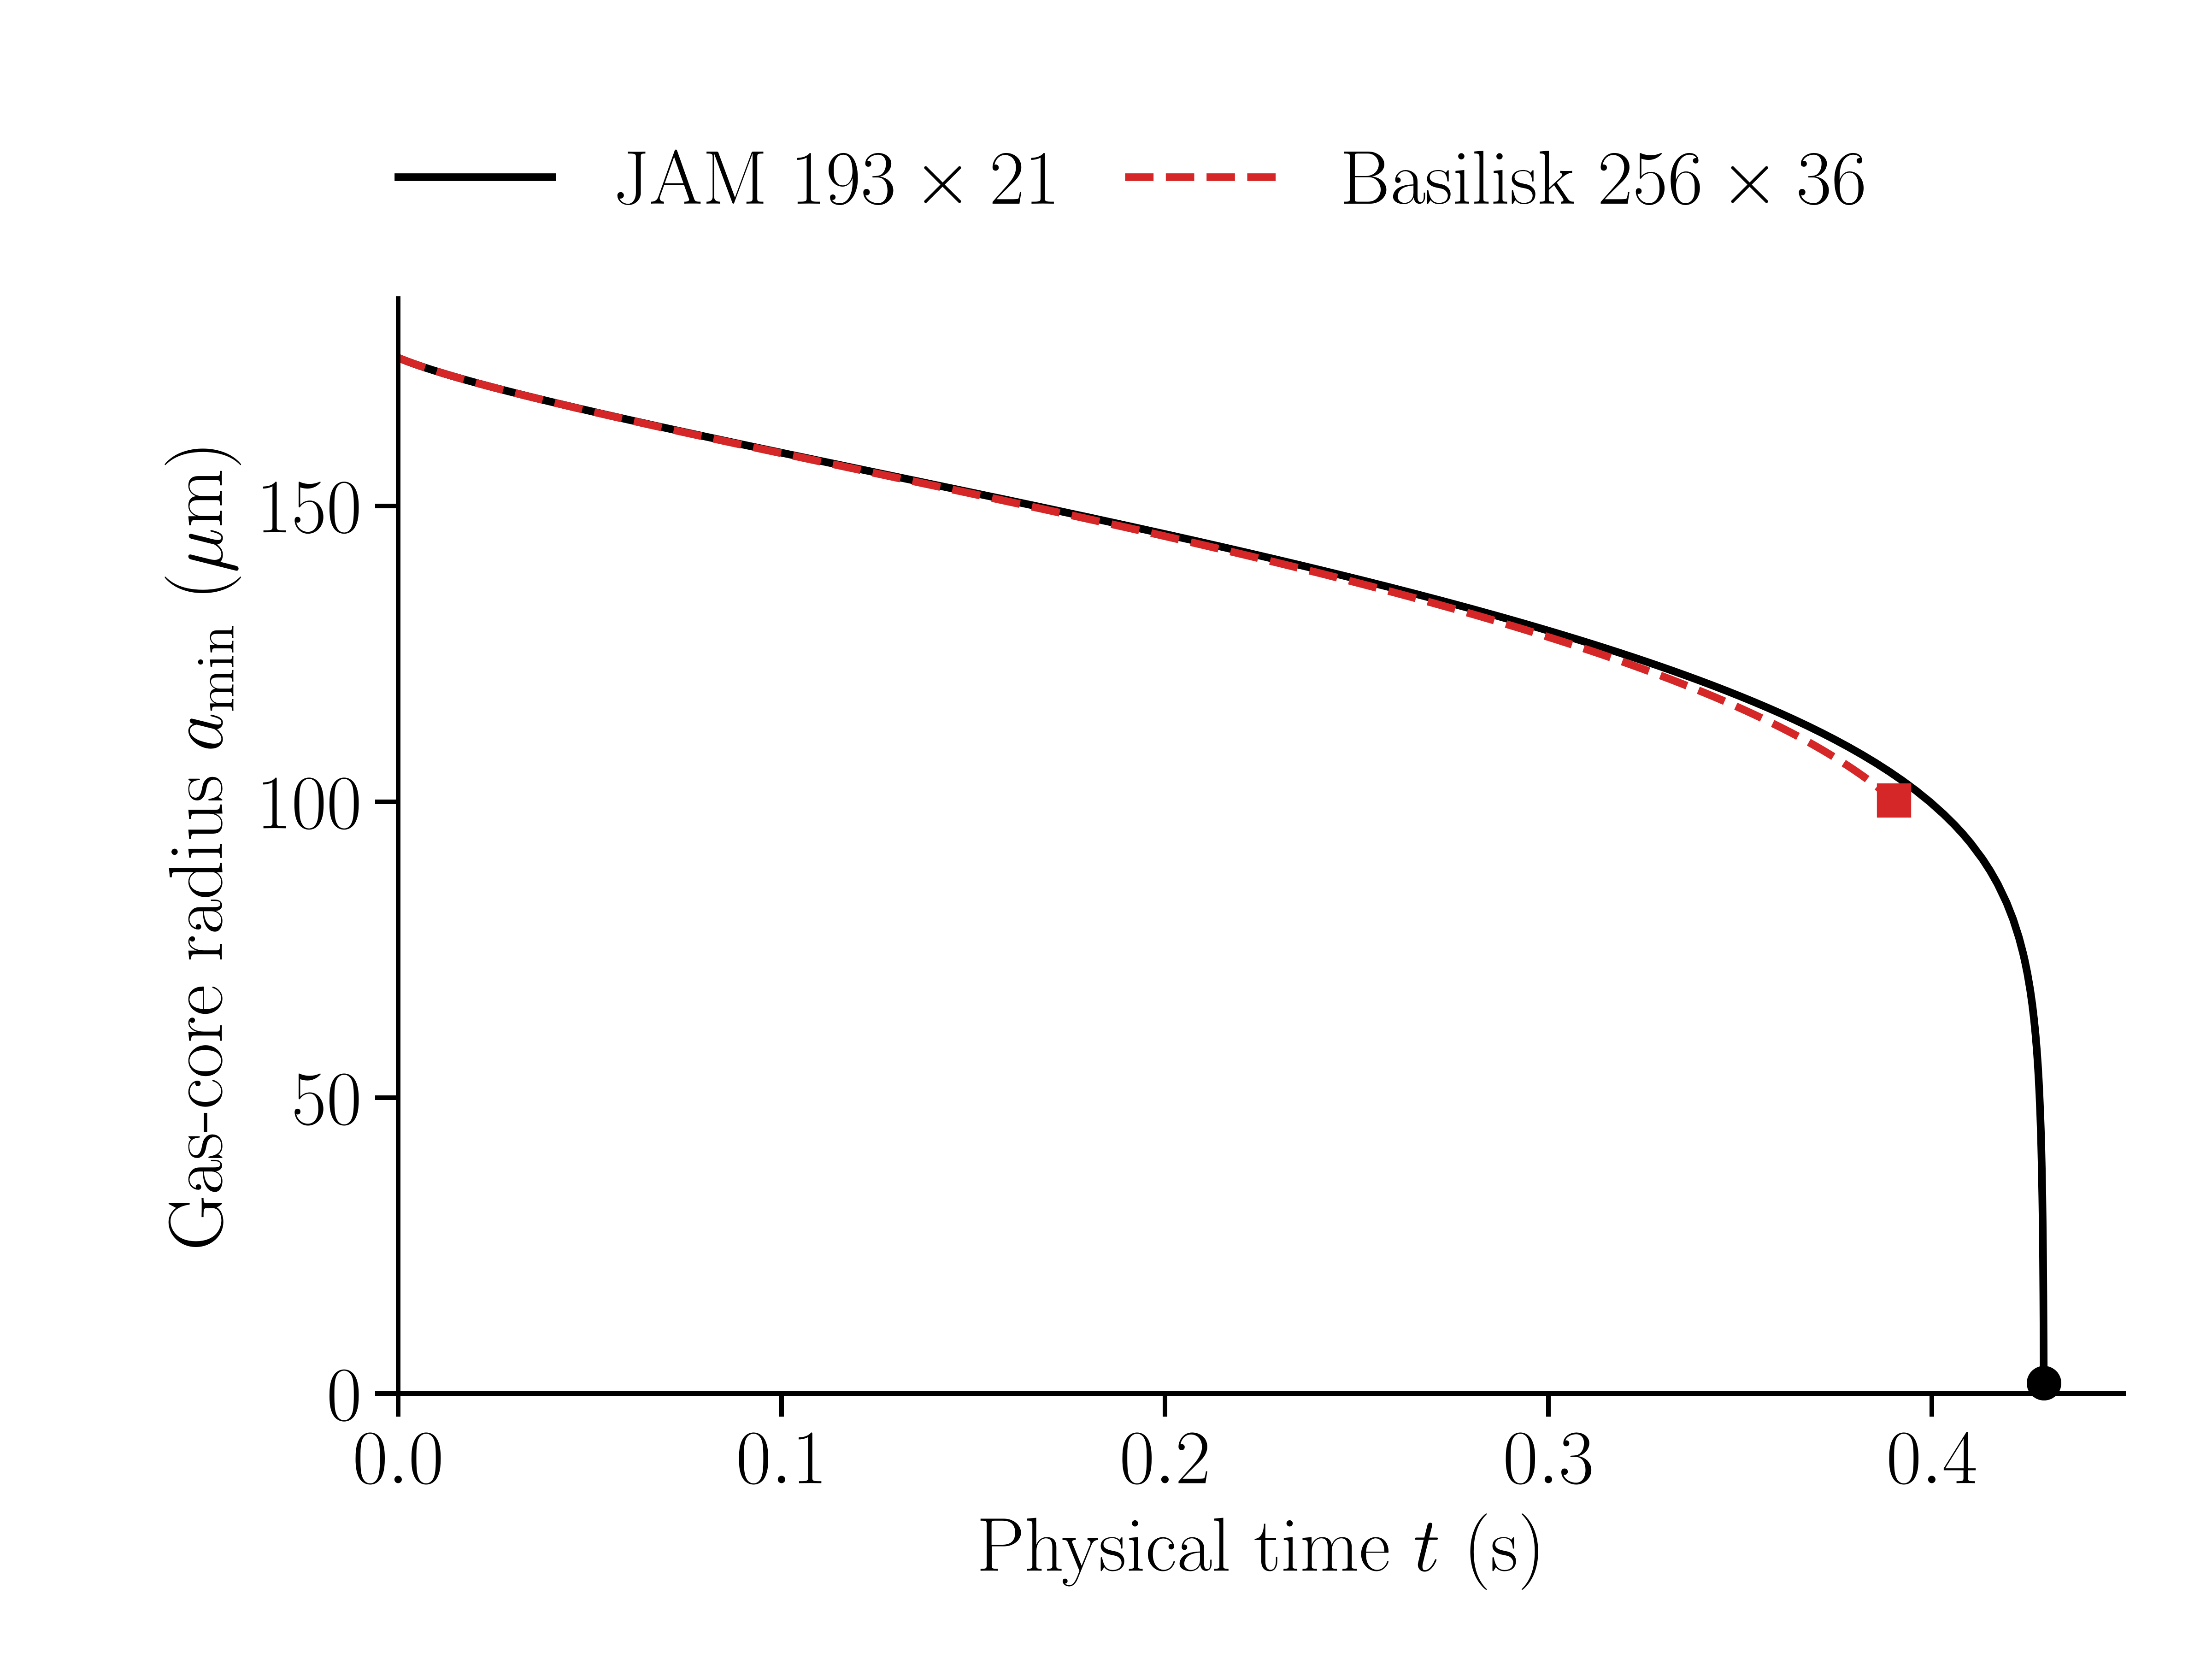

In [1]:
from pathlib import Path
from IPython.display import Image, display

here = Path.cwd()
repo = next(path for path in (here, *here.parents)
            if (path/'results/newtonian/scaling_fit.json').is_file())
inputs = repo/'notebooks/data'
newtonian = repo/'results/newtonian'
figures = repo/'runs/notebook_figures'
figures.mkdir(parents=True, exist_ok=True)
display(Image(filename=str(inputs/'figure_01_original.png'), width=850))

## 图 2 · JAM 与 Basilisk 的剩余时间尺度

两条曲线共用 JAM 末段外推的 $t_{c,\mathrm{JAM}}=0.42920033\,\mathrm{s}$，横轴为 $t_{c,\mathrm{JAM}}-t$。Basilisk 用更新的诊断快照，快照末端气芯仍贯通。蓝色短线是按 JAM 相应区间定位的参考斜率。

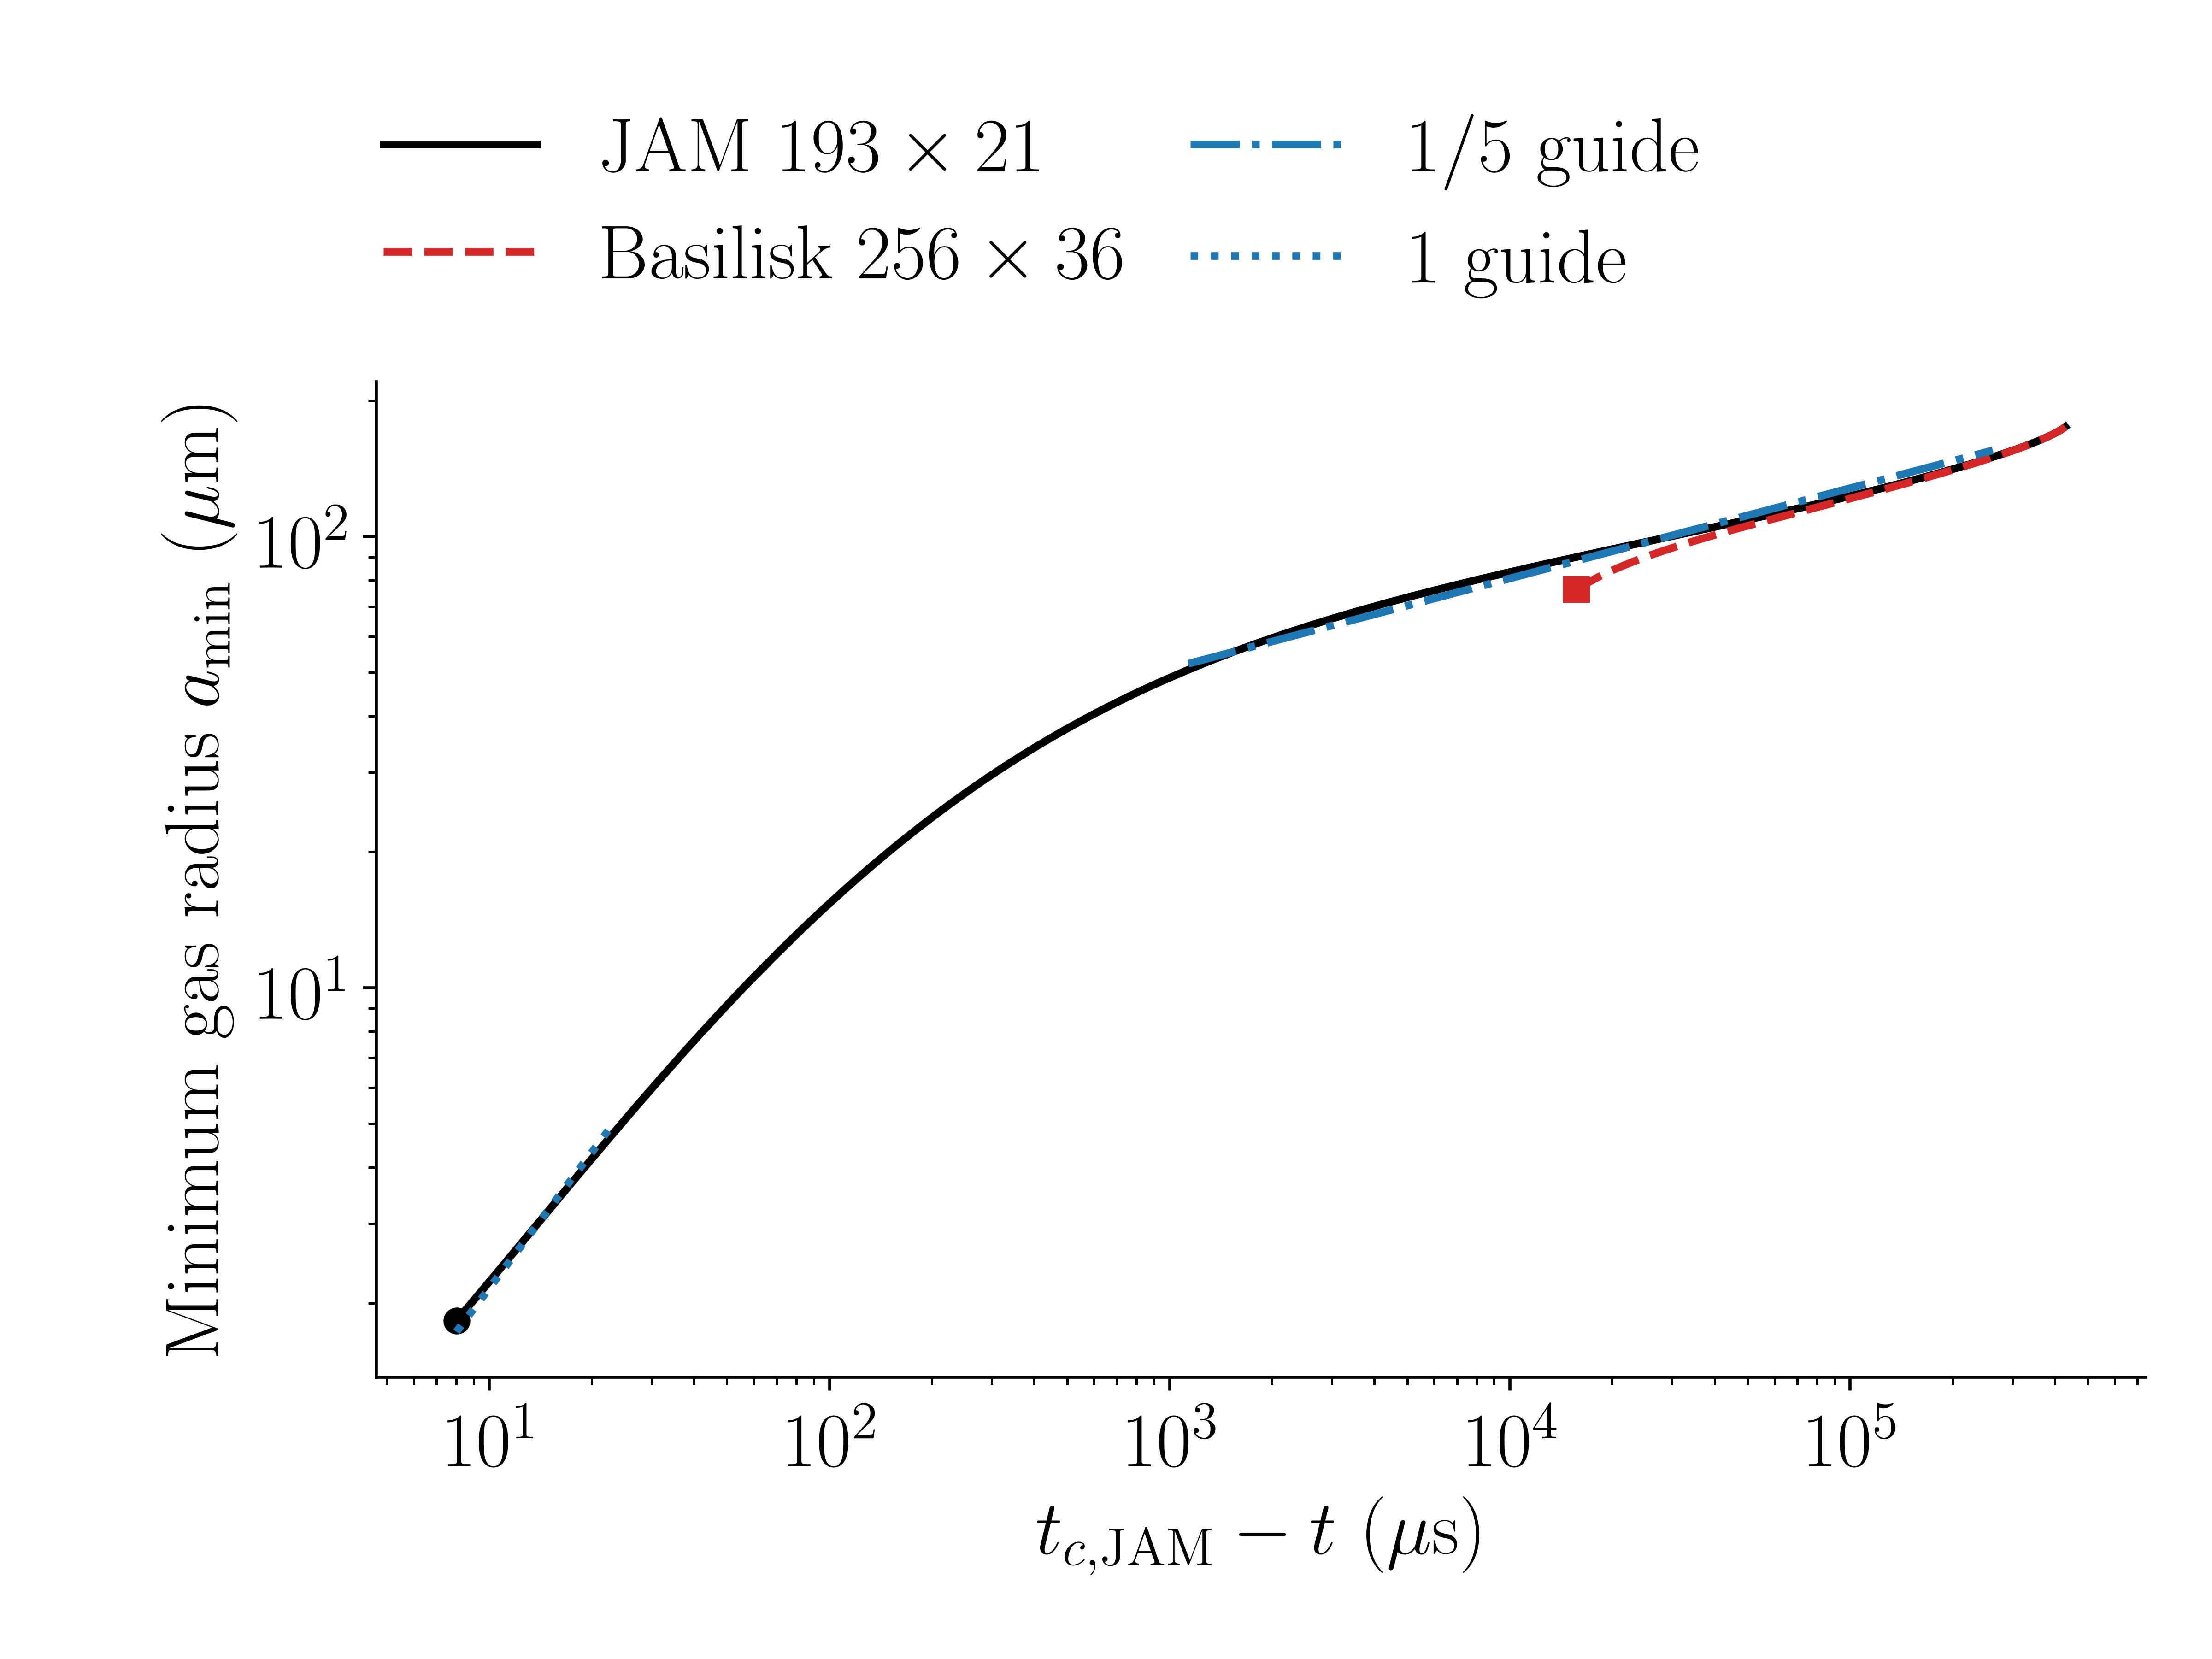

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (8, 6), 'font.family': 'serif', 'font.size': 20,
    'text.usetex': True, 'text.latex.preamble': r'\usepackage{amsmath}',
    'axes.labelsize': 20, 'axes.titlesize': 20, 'axes.grid': False,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.labelsize': 20, 'ytick.labelsize': 20,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'legend.fontsize': 20, 'legend.frameon': False, 'lines.linewidth': 2,
})

tc = json.loads((newtonian/'scaling_fit.json').read_text())['extrapolated_tc_power_s']
jam = pd.read_csv(newtonian/'jam_radius.csv')
basilisk = pd.read_csv(inputs/'basilisk_radius.csv.gz')
assert max(jam.t_s.max(),basilisk.t_s.max()) < tc

def show_figure(figure, stem):
    figure.savefig(figures/(stem+'.pdf'))
    figure.savefig(figures/(stem+'.png'),dpi=600)
    display(Image(filename=str(figures/(stem+'.png')),width=850))
    plt.close(figure)

fig, ax = plt.subplots()
fig.subplots_adjust(left=.17,right=.97,bottom=.17,top=.77)
for data, color, style, marker, name in [
    (jam,'black','-','o',r'JAM $193\times21$'),
    (basilisk,'#D62728','--','s',r'Basilisk $256\times36$'),
]:
    tau = (tc-data.t_s)*1e6
    ax.loglog(tau,data.a_um,color=color,ls=style,label=name)
    ax.loglog(tau.iloc[-1],data.a_um.iloc[-1],marker=marker,color=color)
for power, lower, upper, label in [(0.2,50,150,r'$1/5$ guide'),(1.,1.82,5.,r'$1$ guide')]:
    window = jam[jam.a_um.between(lower,upper)]
    tau = (tc-window.t_s.to_numpy())*1e6
    weights = abs(np.gradient(np.log(window.a_um)))
    amplitude = np.exp(np.average(np.log(window.a_um)-power*np.log(tau),weights=weights))
    reference = np.geomspace(tau.min(),tau.max(),80)
    ax.loglog(reference,amplitude*reference**power,color='#1F77B4',ls=':' if power==1 else '-.',label=label)
ax.set(xlabel=r'$t_{c,\mathrm{JAM}}-t$ ($\mu$s)',ylabel=r'Minimum gas radius $a_{\min}$ ($\mu$m)')
ax.legend(loc='lower left',bbox_to_anchor=(-.035,1.015),ncol=2,columnspacing=.85)
ax.grid(False,which='both')
show_figure(fig,'04_scaling_jam_basilisk')

图 2 的 Basilisk 快照末点为 **0.413487 s、76.25 μm**。JAM 末点气芯半径为 **1.83 μm**。

## 图 3 · JAM 气颈的自相似轮廓

各帧按最小半径位置 $z_{\min}$ 对齐。纵轴为 $a/a_{\min}$，横轴为 $\xi=(z-z_{\min})/\sqrt{R a_{\min}}$，轴向尺度由同一个管半径 $R$ 和各帧的 $a_{\min}$ 决定。

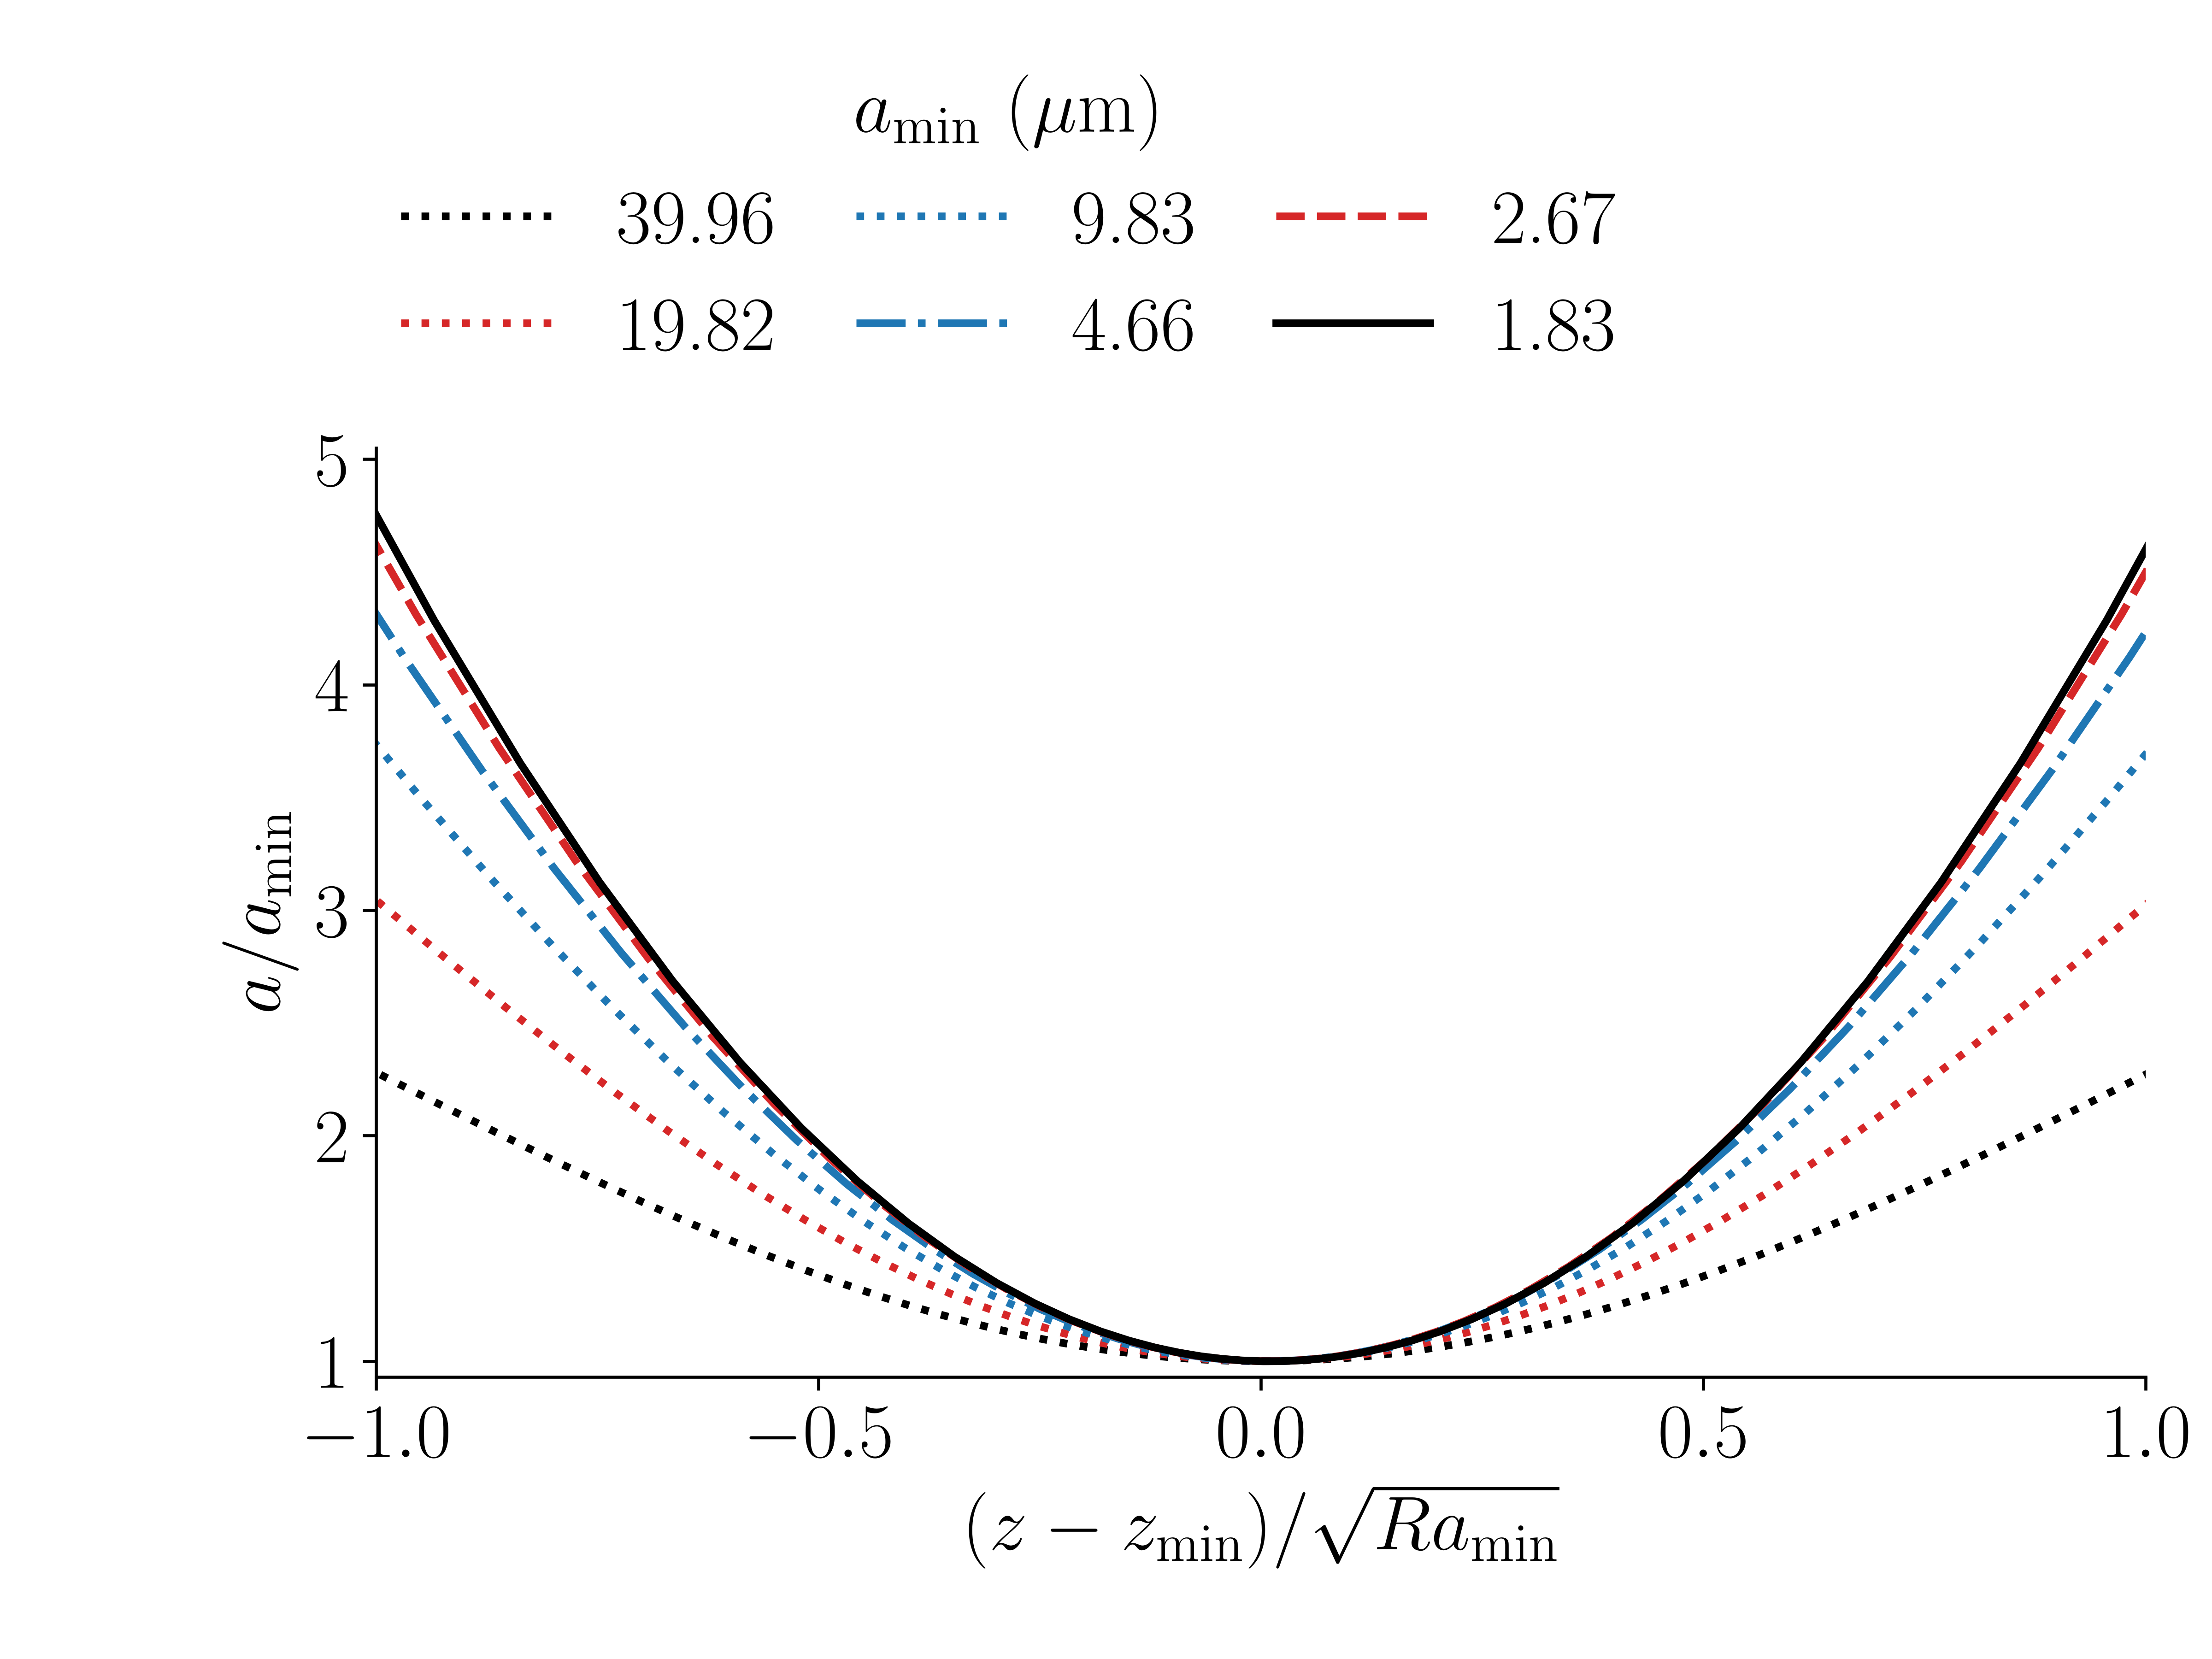

In [3]:
profiles = pd.read_csv(newtonian/'jam_profiles.csv')
fig, ax = plt.subplots()
fig.subplots_adjust(left=.17,right=.97,bottom=.17,top=.73)
styles = [('black',':'),('#D62728',':'),('#1F77B4',':'),
          ('#1F77B4','-.'),('#D62728','--'),('black','-')]
widths = []
for (_, frame), (color, style) in zip(profiles.groupby('frame',sort=False),styles):
    a_min = frame.a_min_um.iloc[0]
    xi = (frame.z_um-frame.z_neck_um.iloc[0]).to_numpy()/np.sqrt(250*a_min)
    shape = (frame.a_um/a_min).to_numpy()
    crossings = []
    for side in [-1,1]:
        indices = np.flatnonzero(side*xi>=0)
        indices = indices[np.argsort(abs(xi[indices]))]
        first = np.flatnonzero(shape[indices]>=2)[0]
        segment = indices[first-1:first+1]
        crossings.append(np.interp(2,shape[segment],abs(xi[segment])))
    widths.append((float(a_min),float(np.mean(crossings))))
    shown = abs(xi)<=1.08
    ax.plot(xi[shown],shape[shown],color=color,ls=style,label=f'{a_min:.2f}')
ax.set(xlabel=r'$(z-z_{\min})/\sqrt{Ra_{\min}}$',ylabel=r'$a/a_{\min}$',
       xlim=(-1,1),ylim=(.93,5.05))
ax.legend(title=r'$a_{\min}$ ($\mu$m)',loc='lower left',
          bbox_to_anchor=(-.025,1.015),ncol=3,columnspacing=1.05)
ax.grid(False,which='both')
show_figure(fig,'05_jam_similarity_profiles')

末段三帧的归一化颈部轮廓靠拢。取半径达到最小半径两倍处的左右轴向半宽，平均后归一化为 **0.521–0.537**。较早的轮廓仍明显分开。
 
数据来自仓库内的牛顿 JAM 轨迹和原场轮廓，以及 Basilisk 作业 47771 的诊断快照。图 1 使用指定原图。图 2、3 的绘图代码可编辑，输出写入 runs/notebook_figures。运行需要 NumPy、Pandas、Matplotlib、IPython 和 LaTeX（含 dvipng）。